# Data Processing Notebook

This notebook covers our data cleaning process. Our dataset is a publicly availble Kaggle dataset called Spotify Music Dataset uploaded by Solomon Ameh, available [here](https://www.kaggle.com/datasets/solomonameh/spotify-music-dataset).

We'll be discretizing continuous variables we want to use, and removing variables we don't intend to train on, removing duplicate observations, etc.

In [1]:
import pandas as pd
import numpy as np

Our data comes as two separate `.csv` files, we'll concatenate them together into a single DataFrame.

In [12]:
high_pop_raw = pd.read_csv('data/high_popularity_spotify_data.csv')
high_pop_raw

,energy,tempo,danceability,playlist_genre,loudness,liveness,valence,track_artist,time_signature,speechiness,...,instrumentalness,track_album_id,mode,key,duration_ms,acousticness,id,playlist_subgenre,type,playlist_id
0,0.592,157.969,0.521,pop,-7.777,0.1220,0.535,"Lady Gaga, Bruno Mars",3,0.0304,...,0.000000,10FLjwfpbxLmW8c25Xyc2N,0,6,251668,0.3080,2plbrEY59IikOBgBGLjaoe,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
1,0.507,104.978,0.747,pop,-10.171,0.1170,0.438,Billie Eilish,4,0.0358,...,0.060800,7aJuG4TFXa2hmE4z1yxc3n,1,2,210373,0.2000,6dOtVTDdiauQNBQEDOtlAB,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
2,0.808,108.548,0.554,pop,-4.169,0.1590,0.372,Gracie Abrams,4,0.0368,...,0.000000,0hBRqPYPXhr1RkTDG3n4Mk,1,1,166300,0.2140,7ne4VBA60CxGM75vw0EYad,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
3,0.910,112.966,0.670,pop,-4.070,0.3040,0.786,Sabrina Carpenter,4,0.0634,...,0.000000,4B4Elma4nNDUyl6D5PvQkj,0,0,157280,0.0939,1d7Ptw3qYcfpdLNL5REhtJ,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
4,0.783,149.027,0.777,pop,-4.477,0.3550,0.939,"ROSÉ, Bruno Mars",4,0.2600,...,0.000000,2IYQwwgxgOIn7t3iF6ufFD,0,0,169917,0.0283,5vNRhkKd0yEAg8suGBpjeY,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1681,0.422,124.357,0.573,latin,-7.621,0.1020,0.693,Libianca,5,0.0678,...,0.000013,5Hmh6N8oisrcuZKa8EY5dn,0,10,184791,0.5510,26b3oVLrRUaaybJulow9kz,afro-latin,audio_features,0oU30cCr8klmMsuOKHDLkh
1682,0.725,105.016,0.711,latin,-8.315,0.1100,0.530,Omah Lay,4,0.0941,...,0.129000,5NLjxx8nRy9ooUmgpOvfem,0,3,183057,0.4240,1wADwLSkYhrSmy4vdy6BRn,afro-latin,audio_features,0oU30cCr8klmMsuOKHDLkh
1683,0.809,99.005,0.724,latin,-5.022,0.0765,0.606,"Davido, FAVE",4,0.0929,...,0.000000,6lI21W76LD0S3vC55GrfSS,0,6,194040,0.1820,7vKXc90NT5WBm3UTT4iTVG,afro-latin,audio_features,0oU30cCr8klmMsuOKHDLkh
1684,0.642,83.389,0.463,latin,-4.474,0.0686,0.339,"Future, Drake, Tems",4,0.3400,...,0.000000,6tE9Dnp2zInFij4jKssysL,1,1,189893,0.3140,59nOXPmaKlBfGMDeOVGrIK,afro-latin,audio_features,0oU30cCr8klmMsuOKHDLkh


In [13]:
low_pop_raw = pd.read_csv('data/low_popularity_spotify_data.csv')
low_pop_raw

,time_signature,track_popularity,speechiness,danceability,playlist_name,track_artist,duration_ms,energy,playlist_genre,playlist_subgenre,...,track_album_id,playlist_id,track_id,valence,key,tempo,loudness,acousticness,liveness,track_album_name
0,4.0,23,0.0393,0.636,Rock Classics,Creedence Clearwater Revival,138053.0,0.746,rock,classic,...,4A8gFwqd9jTtnsNwUu3OQx,37i9dQZF1DWXRqgorJj26U,5e6x5YRnMJIKvYpZxLqdpH,0.432,0.0,132.310,-3.785,0.0648,0.1730,The Long Road Home - The Ultimate John Fogerty...
1,4.0,53,0.0317,0.572,Rock Classics,Van Halen,241600.0,0.835,rock,classic,...,2c965LEDRNrXXCeBOAAwns,37i9dQZF1DWXRqgorJj26U,5FqYA8KfiwsQvyBI4IamnY,0.795,0.0,129.981,-6.219,0.1710,0.0702,The Collection
2,4.0,55,0.0454,0.591,Rock Classics,Stevie Nicks,329413.0,0.804,rock,classic,...,3S404OgKoVQSJ3xXrDVlp8,37i9dQZF1DWXRqgorJj26U,5LNiqEqpDc8TuqPy79kDBu,0.658,0.0,111.457,-7.299,0.3270,0.0818,Bella Donna (Deluxe Edition)
3,4.0,64,0.1010,0.443,Jazz Classics,"Ella Fitzgerald, Louis Armstrong",185160.0,0.104,jazz,classic,...,1y5KGkUKO0NG32MhIIagCA,37i9dQZF1DXbITWG1ZJKYt,78MI7mu1LV1k4IA2HzKmHe,0.394,0.0,76.474,-17.042,0.9130,0.1910,"Love, Ella"
4,4.0,62,0.0298,0.685,Jazz Classics,Galt MacDermot,205720.0,0.472,jazz,classic,...,6f4b9wVTkKAf096k4XG6x5,37i9dQZF1DXbITWG1ZJKYt,6MN6yRVriszuyAVlyF8ndB,0.475,9.0,80.487,-9.691,0.7850,0.2240,Shapes of Rhythm/Woman Is Sweeter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3140,1.0,33,0.0634,0.352,Carnatic Classics,M. S. Subbulakshmi,661293.0,0.424,indian,classical,...,5utDQUWCZCEXWHMmna8C63,3sIB6VOssssCO17VUPu80m,1IkR0OgVI1gydC4S6jnG2B,0.605,10.0,75.466,-8.009,0.9650,0.2420,Bhaja Govindam - Vishnu Sahasranamam
3141,4.0,22,0.0656,0.471,Carnatic Classics,Jayanthi Kumaresh,394400.0,0.349,indian,classical,...,4kUGwkHXKBbaLwnqTIrg0J,3sIB6VOssssCO17VUPu80m,4ZFM5yFsjEzvZ1XmP27L5r,0.358,8.0,147.193,-16.633,0.9750,0.2860,Veenai Jayanthi Kumaresh
3142,4.0,18,0.0671,0.436,Carnatic Classics,"Nirmala Rajasekar, Raghavendra Rao, Tanjore K....",473440.0,0.595,indian,classical,...,6FMROVG9PB4nJYmvNLTdge,3sIB6VOssssCO17VUPu80m,5wZQXUcphAyBZfVdWmAiYX,0.870,3.0,174.308,-11.494,0.8160,0.0939,Into the Raga
3143,1.0,23,0.0813,0.489,Carnatic Classics,Ganesh & Kumaresh,298987.0,0.591,indian,classical,...,3si4Lr5oBcahJ3D7IPbO4N,3sIB6VOssssCO17VUPu80m,5Ca5l5vDzIOZdVwwWCxAds,0.689,8.0,174.760,-10.843,0.9480,0.0770,Thillanas: A Confluence Of Rhythm & Melody


In [79]:
spotify_raw = pd.concat([high_pop_raw, low_pop_raw]).reset_index(drop=True)
spotify_raw

,energy,tempo,danceability,playlist_genre,loudness,liveness,valence,track_artist,time_signature,speechiness,...,instrumentalness,track_album_id,mode,key,duration_ms,acousticness,id,playlist_subgenre,type,playlist_id
0,0.592,157.969,0.521,pop,-7.777,0.1220,0.535,"Lady Gaga, Bruno Mars",3.0,0.0304,...,0.0000,10FLjwfpbxLmW8c25Xyc2N,0.0,6.0,251668.0,0.3080,2plbrEY59IikOBgBGLjaoe,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
1,0.507,104.978,0.747,pop,-10.171,0.1170,0.438,Billie Eilish,4.0,0.0358,...,0.0608,7aJuG4TFXa2hmE4z1yxc3n,1.0,2.0,210373.0,0.2000,6dOtVTDdiauQNBQEDOtlAB,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
2,0.808,108.548,0.554,pop,-4.169,0.1590,0.372,Gracie Abrams,4.0,0.0368,...,0.0000,0hBRqPYPXhr1RkTDG3n4Mk,1.0,1.0,166300.0,0.2140,7ne4VBA60CxGM75vw0EYad,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
3,0.910,112.966,0.670,pop,-4.070,0.3040,0.786,Sabrina Carpenter,4.0,0.0634,...,0.0000,4B4Elma4nNDUyl6D5PvQkj,0.0,0.0,157280.0,0.0939,1d7Ptw3qYcfpdLNL5REhtJ,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
4,0.783,149.027,0.777,pop,-4.477,0.3550,0.939,"ROSÉ, Bruno Mars",4.0,0.2600,...,0.0000,2IYQwwgxgOIn7t3iF6ufFD,0.0,0.0,169917.0,0.0283,5vNRhkKd0yEAg8suGBpjeY,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4826,0.424,75.466,0.352,indian,-8.009,0.2420,0.605,M. S. Subbulakshmi,1.0,0.0634,...,0.0000,5utDQUWCZCEXWHMmna8C63,1.0,10.0,661293.0,0.9650,1IkR0OgVI1gydC4S6jnG2B,classical,audio_features,3sIB6VOssssCO17VUPu80m
4827,0.349,147.193,0.471,indian,-16.633,0.2860,0.358,Jayanthi Kumaresh,4.0,0.0656,...,0.9450,4kUGwkHXKBbaLwnqTIrg0J,1.0,8.0,394400.0,0.9750,4ZFM5yFsjEzvZ1XmP27L5r,classical,audio_features,3sIB6VOssssCO17VUPu80m
4828,0.595,174.308,0.436,indian,-11.494,0.0939,0.870,"Nirmala Rajasekar, Raghavendra Rao, Tanjore K....",4.0,0.0671,...,0.8680,6FMROVG9PB4nJYmvNLTdge,1.0,3.0,473440.0,0.8160,5wZQXUcphAyBZfVdWmAiYX,classical,audio_features,3sIB6VOssssCO17VUPu80m
4829,0.591,174.760,0.489,indian,-10.843,0.0770,0.689,Ganesh & Kumaresh,1.0,0.0813,...,0.9270,3si4Lr5oBcahJ3D7IPbO4N,0.0,8.0,298987.0,0.9480,5Ca5l5vDzIOZdVwwWCxAds,classical,audio_features,3sIB6VOssssCO17VUPu80m


Our dataset features 29 variables, and 4,831 observations.

## Cleaning

The data is already quite clean, and features almost no missing values. As a result, cleaning will mostly involve removing duplicate observations, and unneeded variables.  

### Removing Duplicates

We'll remove duplicates by finding all songs that have the same `track_name` and `track_artist`. (The `track_id` feature is slightly unreliable, as some songs have two different `track_id`s).

In [80]:
no_dupes = spotify_raw.drop_duplicates(subset=['track_name', 'track_artist'])
no_dupes

,energy,tempo,danceability,playlist_genre,loudness,liveness,valence,track_artist,time_signature,speechiness,...,instrumentalness,track_album_id,mode,key,duration_ms,acousticness,id,playlist_subgenre,type,playlist_id
0,0.592,157.969,0.521,pop,-7.777,0.1220,0.535,"Lady Gaga, Bruno Mars",3.0,0.0304,...,0.0000,10FLjwfpbxLmW8c25Xyc2N,0.0,6.0,251668.0,0.3080,2plbrEY59IikOBgBGLjaoe,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
1,0.507,104.978,0.747,pop,-10.171,0.1170,0.438,Billie Eilish,4.0,0.0358,...,0.0608,7aJuG4TFXa2hmE4z1yxc3n,1.0,2.0,210373.0,0.2000,6dOtVTDdiauQNBQEDOtlAB,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
2,0.808,108.548,0.554,pop,-4.169,0.1590,0.372,Gracie Abrams,4.0,0.0368,...,0.0000,0hBRqPYPXhr1RkTDG3n4Mk,1.0,1.0,166300.0,0.2140,7ne4VBA60CxGM75vw0EYad,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
3,0.910,112.966,0.670,pop,-4.070,0.3040,0.786,Sabrina Carpenter,4.0,0.0634,...,0.0000,4B4Elma4nNDUyl6D5PvQkj,0.0,0.0,157280.0,0.0939,1d7Ptw3qYcfpdLNL5REhtJ,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
4,0.783,149.027,0.777,pop,-4.477,0.3550,0.939,"ROSÉ, Bruno Mars",4.0,0.2600,...,0.0000,2IYQwwgxgOIn7t3iF6ufFD,0.0,0.0,169917.0,0.0283,5vNRhkKd0yEAg8suGBpjeY,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4826,0.424,75.466,0.352,indian,-8.009,0.2420,0.605,M. S. Subbulakshmi,1.0,0.0634,...,0.0000,5utDQUWCZCEXWHMmna8C63,1.0,10.0,661293.0,0.9650,1IkR0OgVI1gydC4S6jnG2B,classical,audio_features,3sIB6VOssssCO17VUPu80m
4827,0.349,147.193,0.471,indian,-16.633,0.2860,0.358,Jayanthi Kumaresh,4.0,0.0656,...,0.9450,4kUGwkHXKBbaLwnqTIrg0J,1.0,8.0,394400.0,0.9750,4ZFM5yFsjEzvZ1XmP27L5r,classical,audio_features,3sIB6VOssssCO17VUPu80m
4828,0.595,174.308,0.436,indian,-11.494,0.0939,0.870,"Nirmala Rajasekar, Raghavendra Rao, Tanjore K....",4.0,0.0671,...,0.8680,6FMROVG9PB4nJYmvNLTdge,1.0,3.0,473440.0,0.8160,5wZQXUcphAyBZfVdWmAiYX,classical,audio_features,3sIB6VOssssCO17VUPu80m
4829,0.591,174.760,0.489,indian,-10.843,0.0770,0.689,Ganesh & Kumaresh,1.0,0.0813,...,0.9270,3si4Lr5oBcahJ3D7IPbO4N,0.0,8.0,298987.0,0.9480,5Ca5l5vDzIOZdVwwWCxAds,classical,audio_features,3sIB6VOssssCO17VUPu80m


### Removing Missing Values

The dataset features two observations with missing values. Given the size of our dataset, these form a negligble portion our data, and can be removed as outliers. 

In [81]:
no_null = no_dupes.dropna()
no_null

,energy,tempo,danceability,playlist_genre,loudness,liveness,valence,track_artist,time_signature,speechiness,...,instrumentalness,track_album_id,mode,key,duration_ms,acousticness,id,playlist_subgenre,type,playlist_id
0,0.592,157.969,0.521,pop,-7.777,0.1220,0.535,"Lady Gaga, Bruno Mars",3.0,0.0304,...,0.0000,10FLjwfpbxLmW8c25Xyc2N,0.0,6.0,251668.0,0.3080,2plbrEY59IikOBgBGLjaoe,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
1,0.507,104.978,0.747,pop,-10.171,0.1170,0.438,Billie Eilish,4.0,0.0358,...,0.0608,7aJuG4TFXa2hmE4z1yxc3n,1.0,2.0,210373.0,0.2000,6dOtVTDdiauQNBQEDOtlAB,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
2,0.808,108.548,0.554,pop,-4.169,0.1590,0.372,Gracie Abrams,4.0,0.0368,...,0.0000,0hBRqPYPXhr1RkTDG3n4Mk,1.0,1.0,166300.0,0.2140,7ne4VBA60CxGM75vw0EYad,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
3,0.910,112.966,0.670,pop,-4.070,0.3040,0.786,Sabrina Carpenter,4.0,0.0634,...,0.0000,4B4Elma4nNDUyl6D5PvQkj,0.0,0.0,157280.0,0.0939,1d7Ptw3qYcfpdLNL5REhtJ,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
4,0.783,149.027,0.777,pop,-4.477,0.3550,0.939,"ROSÉ, Bruno Mars",4.0,0.2600,...,0.0000,2IYQwwgxgOIn7t3iF6ufFD,0.0,0.0,169917.0,0.0283,5vNRhkKd0yEAg8suGBpjeY,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4826,0.424,75.466,0.352,indian,-8.009,0.2420,0.605,M. S. Subbulakshmi,1.0,0.0634,...,0.0000,5utDQUWCZCEXWHMmna8C63,1.0,10.0,661293.0,0.9650,1IkR0OgVI1gydC4S6jnG2B,classical,audio_features,3sIB6VOssssCO17VUPu80m
4827,0.349,147.193,0.471,indian,-16.633,0.2860,0.358,Jayanthi Kumaresh,4.0,0.0656,...,0.9450,4kUGwkHXKBbaLwnqTIrg0J,1.0,8.0,394400.0,0.9750,4ZFM5yFsjEzvZ1XmP27L5r,classical,audio_features,3sIB6VOssssCO17VUPu80m
4828,0.595,174.308,0.436,indian,-11.494,0.0939,0.870,"Nirmala Rajasekar, Raghavendra Rao, Tanjore K....",4.0,0.0671,...,0.8680,6FMROVG9PB4nJYmvNLTdge,1.0,3.0,473440.0,0.8160,5wZQXUcphAyBZfVdWmAiYX,classical,audio_features,3sIB6VOssssCO17VUPu80m
4829,0.591,174.760,0.489,indian,-10.843,0.0770,0.689,Ganesh & Kumaresh,1.0,0.0813,...,0.9270,3si4Lr5oBcahJ3D7IPbO4N,0.0,8.0,298987.0,0.9480,5Ca5l5vDzIOZdVwwWCxAds,classical,audio_features,3sIB6VOssssCO17VUPu80m


### Removing Unneeded Features

The `id` columns are not necessary, as they provide little value for inference. All identical songs have already been removed, so we can now remove these columns.

In [82]:
no_id = no_null.drop(columns=no_dupes.columns[no_dupes.columns.str.contains('_id')]).drop(columns=['id'])
no_id

,energy,tempo,danceability,playlist_genre,loudness,liveness,valence,track_artist,time_signature,speechiness,...,analysis_url,track_name,track_album_release_date,instrumentalness,mode,key,duration_ms,acousticness,playlist_subgenre,type
0,0.592,157.969,0.521,pop,-7.777,0.1220,0.535,"Lady Gaga, Bruno Mars",3.0,0.0304,...,https://api.spotify.com/v1/audio-analysis/2plb...,Die With A Smile,2024-08-16,0.0000,0.0,6.0,251668.0,0.3080,mainstream,audio_features
1,0.507,104.978,0.747,pop,-10.171,0.1170,0.438,Billie Eilish,4.0,0.0358,...,https://api.spotify.com/v1/audio-analysis/6dOt...,BIRDS OF A FEATHER,2024-05-17,0.0608,1.0,2.0,210373.0,0.2000,mainstream,audio_features
2,0.808,108.548,0.554,pop,-4.169,0.1590,0.372,Gracie Abrams,4.0,0.0368,...,https://api.spotify.com/v1/audio-analysis/7ne4...,That’s So True,2024-10-18,0.0000,1.0,1.0,166300.0,0.2140,mainstream,audio_features
3,0.910,112.966,0.670,pop,-4.070,0.3040,0.786,Sabrina Carpenter,4.0,0.0634,...,https://api.spotify.com/v1/audio-analysis/1d7P...,Taste,2024-08-23,0.0000,0.0,0.0,157280.0,0.0939,mainstream,audio_features
4,0.783,149.027,0.777,pop,-4.477,0.3550,0.939,"ROSÉ, Bruno Mars",4.0,0.2600,...,https://api.spotify.com/v1/audio-analysis/5vNR...,APT.,2024-10-18,0.0000,0.0,0.0,169917.0,0.0283,mainstream,audio_features
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4826,0.424,75.466,0.352,indian,-8.009,0.2420,0.605,M. S. Subbulakshmi,1.0,0.0634,...,https://api.spotify.com/v1/audio-analysis/1IkR...,Bhaja Govindam,2013-01-18,0.0000,1.0,10.0,661293.0,0.9650,classical,audio_features
4827,0.349,147.193,0.471,indian,-16.633,0.2860,0.358,Jayanthi Kumaresh,4.0,0.0656,...,https://api.spotify.com/v1/audio-analysis/4ZFM...,Varnam,2002-12-01,0.9450,1.0,8.0,394400.0,0.9750,classical,audio_features
4828,0.595,174.308,0.436,indian,-11.494,0.0939,0.870,"Nirmala Rajasekar, Raghavendra Rao, Tanjore K....",4.0,0.0671,...,https://api.spotify.com/v1/audio-analysis/5wZQ...,"Sarasuda Varnam (Raga Saveri, Aadi Tala): Jaya...",2010-10-26,0.8680,1.0,3.0,473440.0,0.8160,classical,audio_features
4829,0.591,174.760,0.489,indian,-10.843,0.0770,0.689,Ganesh & Kumaresh,1.0,0.0813,...,https://api.spotify.com/v1/audio-analysis/5Ca5...,Raga Karnaranjani,2007-01-01,0.9270,0.0,8.0,298987.0,0.9480,classical,audio_features


Next we'll drop `playlist_name`, and `track_album_name` since we will not be considering playlists or albums the songs are a part of in our model as a simplifying assumption. However, we will be keeping columns like `track_name` and `track_artist` as these helps us identify songs. We're also dropping columns like `track_href` or `analysis_url` which are either identifiers and links to supplementary information about the track.

In [83]:
no_playlist = no_id.drop(columns=['playlist_name', 'track_album_name','analysis_url','uri','track_href','type'])
no_playlist

,energy,tempo,danceability,playlist_genre,loudness,liveness,valence,track_artist,time_signature,speechiness,track_popularity,track_name,track_album_release_date,instrumentalness,mode,key,duration_ms,acousticness,playlist_subgenre
0,0.592,157.969,0.521,pop,-7.777,0.1220,0.535,"Lady Gaga, Bruno Mars",3.0,0.0304,100,Die With A Smile,2024-08-16,0.0000,0.0,6.0,251668.0,0.3080,mainstream
1,0.507,104.978,0.747,pop,-10.171,0.1170,0.438,Billie Eilish,4.0,0.0358,97,BIRDS OF A FEATHER,2024-05-17,0.0608,1.0,2.0,210373.0,0.2000,mainstream
2,0.808,108.548,0.554,pop,-4.169,0.1590,0.372,Gracie Abrams,4.0,0.0368,93,That’s So True,2024-10-18,0.0000,1.0,1.0,166300.0,0.2140,mainstream
3,0.910,112.966,0.670,pop,-4.070,0.3040,0.786,Sabrina Carpenter,4.0,0.0634,81,Taste,2024-08-23,0.0000,0.0,0.0,157280.0,0.0939,mainstream
4,0.783,149.027,0.777,pop,-4.477,0.3550,0.939,"ROSÉ, Bruno Mars",4.0,0.2600,98,APT.,2024-10-18,0.0000,0.0,0.0,169917.0,0.0283,mainstream
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4826,0.424,75.466,0.352,indian,-8.009,0.2420,0.605,M. S. Subbulakshmi,1.0,0.0634,33,Bhaja Govindam,2013-01-18,0.0000,1.0,10.0,661293.0,0.9650,classical
4827,0.349,147.193,0.471,indian,-16.633,0.2860,0.358,Jayanthi Kumaresh,4.0,0.0656,22,Varnam,2002-12-01,0.9450,1.0,8.0,394400.0,0.9750,classical
4828,0.595,174.308,0.436,indian,-11.494,0.0939,0.870,"Nirmala Rajasekar, Raghavendra Rao, Tanjore K....",4.0,0.0671,18,"Sarasuda Varnam (Raga Saveri, Aadi Tala): Jaya...",2010-10-26,0.8680,1.0,3.0,473440.0,0.8160,classical
4829,0.591,174.760,0.489,indian,-10.843,0.0770,0.689,Ganesh & Kumaresh,1.0,0.0813,23,Raga Karnaranjani,2007-01-01,0.9270,0.0,8.0,298987.0,0.9480,classical


Next, we will remove features that we will not find useful in our belief network. These simplifying assumptions will help reduce the complexity of our belief network. Reducing the number of variables in our processed dataset helps reduce the number of nodes, and thus, CPTs in our network, while choosing variables, or discretizing them in a way such that they take on less values, will make these CPTs smaller.

Almost all the songs in our dataset are in 4/4 time, as seen on this histogram below. As a result, learning the `time_signature` of a song provides us little information about it's popularity.

<Axes: >

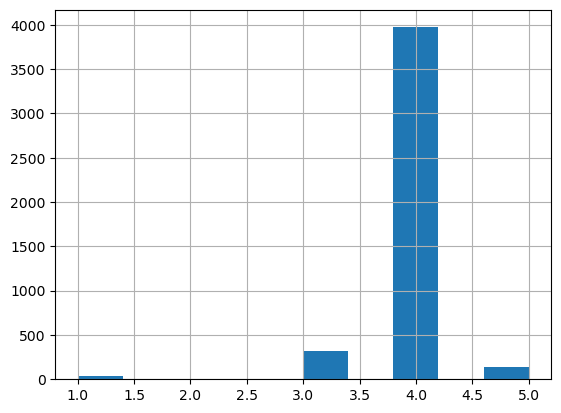

In [84]:
no_playlist['time_signature'].hist()

`instrumentalness` is a continuous variable that measures how instrumental the song is. Presence of speech and other qualities will lower this value. Almost all observations in our dataset are 0, or incredibly close to 0. This makes it poor for inference, providing little new information. As a result, we'll be dropping this column.

<Axes: >

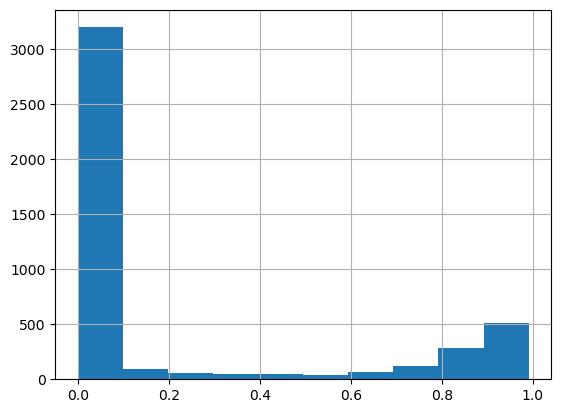

In [85]:
no_playlist['instrumentalness'].hist()

As a result, `speechiness`—a variable which measures the presence of spoken words on the track—which has a similar "long tail" distribution, will also be dropped.

<Axes: >

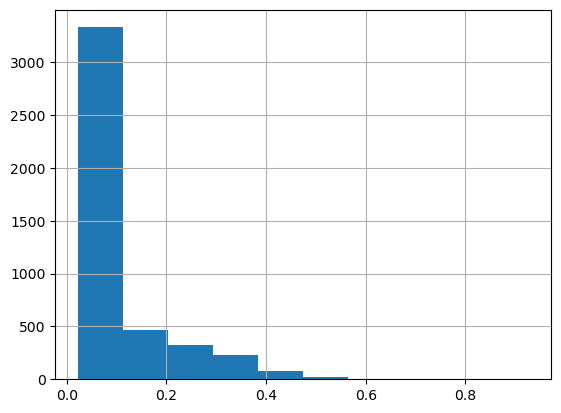

In [98]:
no_playlist['speechiness'].hist()

`playlist_genre` and `playlist_subgenre` informs us about the genre of the playlist a song is in, but not the song itself. It also has at least 30 unique values as a categorical variable each, which will make inference and training more complex. As a result, we'll remove these columns too.

In [93]:
no_playlist['playlist_genre'].unique()

<StringArray>
[       'pop',       'rock',       'jazz',  'classical',    'hip-hop',
  'afrobeats',      'latin',     'indian',    'country',        'r&b',
 'electronic',       'soul',     'gaming',      'j-pop',      'metal',
     'reggae',      'k-pop',     'arabic',       'punk',      'blues',
       'folk',       'lofi',  'brazilian',    'turkish',    'ambient',
     'korean',      'world',      'indie',   'mandopop',   'cantopop',
   'wellness',     'gospel',       'funk',       'soca',      'disco']
Length: 35, dtype: str

In [94]:
no_playlist['playlist_subgenre'].unique()

<StringArray>
[    'mainstream',        'classic',      'essential',         'modern',
       'gangster',           'trap',       'nigerian',        'hip-hop',
      'bollywood',          'indie',      'feel-good',        'african',
          'anime',            '90s',            '80s',         'french',
         'global',          'chill',           'soft',      'throwback',
        'bedroom',    'alternative',          'heavy',       'pop punk',
       'southern',       'american',        'bhangra',       'tropical',
         'techno',    'future bass',         'cumbia',      'reggaeton',
           'funk',            'pop',     'meditative',       'academic',
        'melodic',          'drama', 'throat singing',         'nordic',
           'desi',     'afro house',  'neo-classical',      'vaporwave',
          'drill',        'spanish',        'workout',     'australian',
     'afro-latin',         'scandi',          'death',          'delta',
      'classical',         'smooth', 

`liveness` measures how likely the song is performed live (i.e. in front of an audience). Our model is more concerned with aspects about the song's composition, rather than the context in which it's performed, as a result, we will remove this, and not be using it for inference.

We'll be removing `loudness`, because of its high association with the `energy` variable. Knowing the value of one variable already tells us a lot about the value of the other, which makes keeping both slightly redundant.

<Axes: xlabel='energy', ylabel='loudness'>

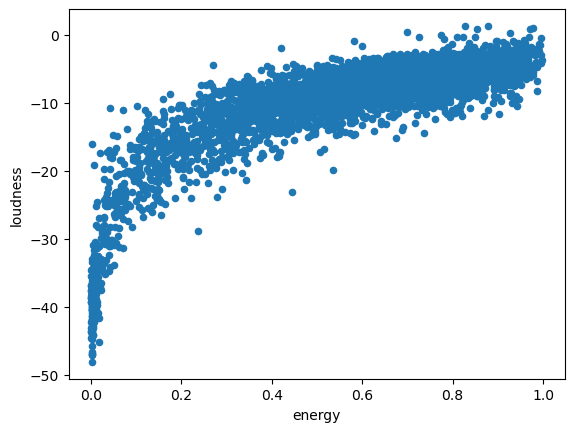

In [123]:
no_playlist.plot.scatter('energy','loudness')

In [125]:
spotify_cleaned = no_playlist.drop(columns=['time_signature', 'instrumentalness', 'speechiness','liveness', 'playlist_genre','playlist_subgenre', 'loudness'])
spotify_cleaned

,energy,tempo,danceability,valence,track_artist,track_popularity,track_name,track_album_release_date,mode,key,duration_ms,acousticness
0,0.592,157.969,0.521,0.535,"Lady Gaga, Bruno Mars",100,Die With A Smile,2024-08-16,0.0,6.0,251668.0,0.3080
1,0.507,104.978,0.747,0.438,Billie Eilish,97,BIRDS OF A FEATHER,2024-05-17,1.0,2.0,210373.0,0.2000
2,0.808,108.548,0.554,0.372,Gracie Abrams,93,That’s So True,2024-10-18,1.0,1.0,166300.0,0.2140
3,0.910,112.966,0.670,0.786,Sabrina Carpenter,81,Taste,2024-08-23,0.0,0.0,157280.0,0.0939
4,0.783,149.027,0.777,0.939,"ROSÉ, Bruno Mars",98,APT.,2024-10-18,0.0,0.0,169917.0,0.0283
...,...,...,...,...,...,...,...,...,...,...,...,...
4826,0.424,75.466,0.352,0.605,M. S. Subbulakshmi,33,Bhaja Govindam,2013-01-18,1.0,10.0,661293.0,0.9650
4827,0.349,147.193,0.471,0.358,Jayanthi Kumaresh,22,Varnam,2002-12-01,1.0,8.0,394400.0,0.9750
4828,0.595,174.308,0.436,0.870,"Nirmala Rajasekar, Raghavendra Rao, Tanjore K....",18,"Sarasuda Varnam (Raga Saveri, Aadi Tala): Jaya...",2010-10-26,1.0,3.0,473440.0,0.8160
4829,0.591,174.760,0.489,0.689,Ganesh & Kumaresh,23,Raga Karnaranjani,2007-01-01,0.0,8.0,298987.0,0.9480


## Discretization

Our dataset contains many continuous variables. We'll need to bin these values to turn them into categories that we can train our network on. For most variables we prefer a discretization that maintains the general shape of the continuous distribution, so we'll bin with equally sized bins for almost all our variables. We want to keep the number of bins low, to avoid complexity, so we'll generally create around 5 bins for each category. We also want the binnings to maintain a decent portion of our observations, so for certain variables where such a binning would results in certain cateegories capturing little amounts of data, these will be modified.



### Popularity

<Axes: >

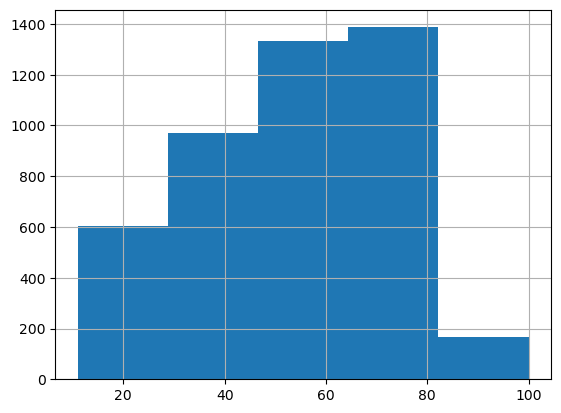

In [144]:
spotify_cleaned['track_popularity'].hist(bins=5)

In [146]:
# pd.cut can bin the values for us
popularity_binned = (
    pd.cut(spotify_cleaned['track_popularity'], bins=np.linspace(0,100,6).astype(int),include_lowest=True)
    .astype(str)
)
popularity_binned

0        (80.0, 100.0]
1        (80.0, 100.0]
2        (80.0, 100.0]
3        (80.0, 100.0]
4        (80.0, 100.0]
             ...      
4826      (20.0, 40.0]
4827      (20.0, 40.0]
4828    (-0.001, 20.0]
4829      (20.0, 40.0]
4830    (-0.001, 20.0]
Name: track_popularity, Length: 4464, dtype: str

### Energy

<Axes: >

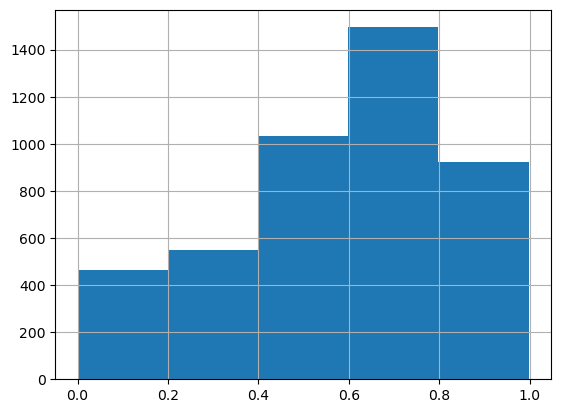

In [145]:
spotify_cleaned['energy'].hist(bins=5)

In [178]:
energy_binned = pd.cut(spotify_cleaned['energy'], bins=np.linspace(0,1,6), include_lowest=True).astype(str)
energy_binned

0       (0.4, 0.6]
1       (0.4, 0.6]
2       (0.8, 1.0]
3       (0.8, 1.0]
4       (0.6, 0.8]
           ...    
4826    (0.4, 0.6]
4827    (0.2, 0.4]
4828    (0.4, 0.6]
4829    (0.4, 0.6]
4830    (0.8, 1.0]
Name: energy, Length: 4464, dtype: str

### Tempo

<Axes: >

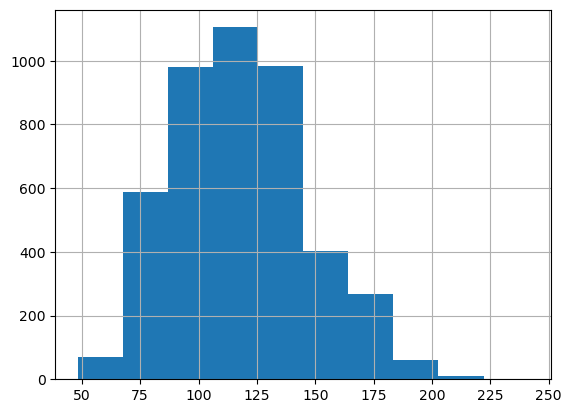

In [176]:
spotify_cleaned['tempo'].hist()

`tempo` has a slight right skew, and binning in equally sized bins will result in categories with very few observations. Instead, we can classify each song into either `slow`, `mid`, `upbeat` or `fast` tempo. Songs under 90 BPM are typically slow ballads. Most pop songs are between 90 and 150 BPM, with a more relaxed song being in the 90-120 BPM range and 120 BPM to 150 for a more upbeat one.

In [180]:
tempo_binned = (
    pd.cut(spotify_cleaned['tempo'], bins=[0, 90, 120, 150, 250], include_lowest=True, labels=['slow', 'mid', 'upbeat', 'fast'])
    .astype(str)
)
tempo_binned

0         fast
1          mid
2          mid
3          mid
4       upbeat
         ...  
4826      slow
4827    upbeat
4828      fast
4829      fast
4830      fast
Name: tempo, Length: 4464, dtype: str

### Duration

<Axes: >

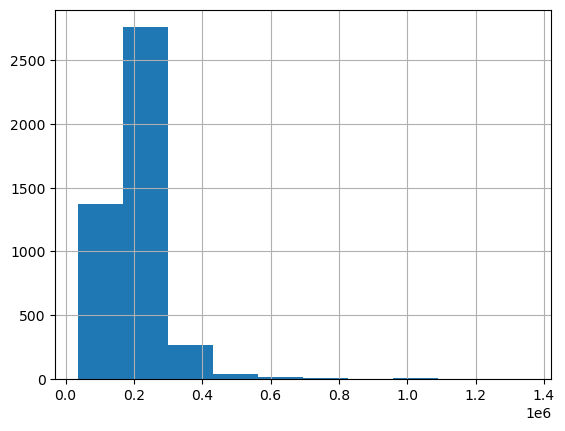

In [194]:
spotify_cleaned['duration_ms'].hist()

We can see that this data has a very long tail. Most songs are between 2 to 4 minutes long. As a result, we'll discretize minute by minute, but combining songs that are less than 2 minutes into one category, and longer than 5 into one category.

In [217]:
duration_binned = (
    pd.cut(spotify_cleaned['duration_ms'], bins=[0, 120000, 180000, 240000, 300000, 1400000], include_lowest=True, labels=['< 2 min', '2-3 min', '3-4 min', '4-5 min', '5+ min'])
    .astype(str)
)
duration_binned

0       4-5 min
1       3-4 min
2       2-3 min
3       2-3 min
4       2-3 min
         ...   
4826     5+ min
4827     5+ min
4828     5+ min
4829    4-5 min
4830     5+ min
Name: duration_ms, Length: 4464, dtype: str

### Valence

<Axes: >

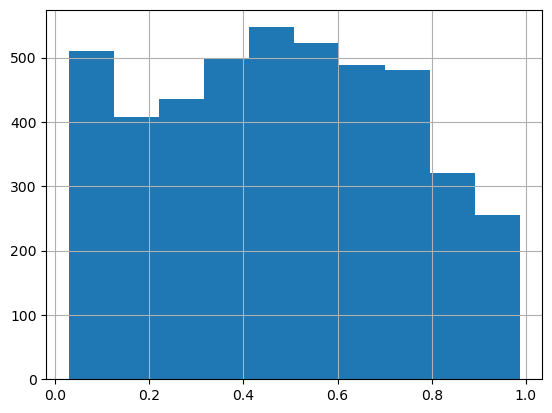

In [195]:
spotify_cleaned['valence'].hist()

In [187]:
valence_binned = pd.cut(spotify_cleaned['valence'], bins=np.linspace(0,1,6), include_lowest=True).astype(str)
valence_binned

0       (0.4, 0.6]
1       (0.4, 0.6]
2       (0.2, 0.4]
3       (0.6, 0.8]
4       (0.8, 1.0]
           ...    
4826    (0.6, 0.8]
4827    (0.2, 0.4]
4828    (0.8, 1.0]
4829    (0.6, 0.8]
4830    (0.4, 0.6]
Name: valence, Length: 4464, dtype: str

### Danceability

<Axes: >

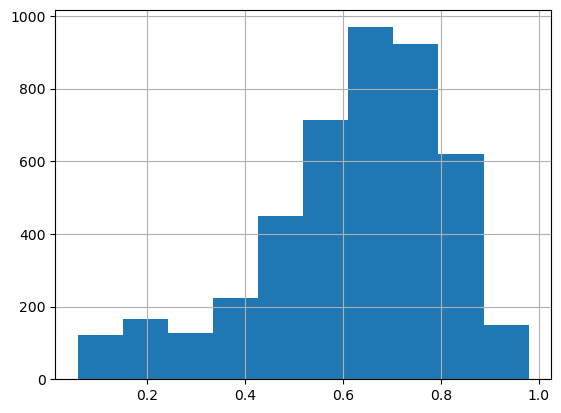

In [196]:
spotify_cleaned['danceability'].hist()

In [192]:
danceability_binned = pd.cut(spotify_cleaned['danceability'], bins=np.linspace(0,1,6), include_lowest=True).astype(str)
danceability_binned

0       (0.4, 0.6]
1       (0.6, 0.8]
2       (0.4, 0.6]
3       (0.6, 0.8]
4       (0.6, 0.8]
           ...    
4826    (0.2, 0.4]
4827    (0.4, 0.6]
4828    (0.4, 0.6]
4829    (0.4, 0.6]
4830    (0.2, 0.4]
Name: danceability, Length: 4464, dtype: str

### Acousticness

<Axes: >

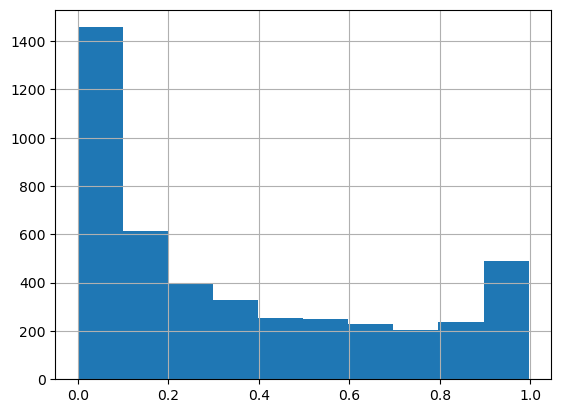

In [226]:
spotify_cleaned['acousticness'].hist()

In [227]:
acousticness_binned = pd.cut(spotify_cleaned['acousticness'], bins=np.linspace(0,1,6), include_lowest=True).astype(str)
acousticness_binned

0          (0.2, 0.4]
1       (-0.001, 0.2]
2          (0.2, 0.4]
3       (-0.001, 0.2]
4       (-0.001, 0.2]
            ...      
4826       (0.8, 1.0]
4827       (0.8, 1.0]
4828       (0.8, 1.0]
4829       (0.8, 1.0]
4830       (0.8, 1.0]
Name: acousticness, Length: 4464, dtype: str

### Transformating Date

We want to transform the date of the release to get a 'release decade' variable. Certain music trends are often period specific, and more recent music may be trendier, and thus, more popular. By transforming this into decade, we can retain this information while keeping the number of bins relatively low. We'll be merging the decades `1950s`, `1960s`, `1970s`, and `1980s`, since by themselves these make up a small number of our observations.

In [208]:

release_date = pd.to_datetime(spotify_cleaned['track_album_release_date'], format='mixed')
release_year = release_date.dt.year
release_decade = (
    pd.cut(release_year, bins=[1950, 1990, 2000, 2010, 2020, 2030], labels=["Before 1990"] + [f"{i}0s" for i in range(199, 203)], include_lowest=True)).astype(str)
release_decade

0       2020s
1       2020s
2       2020s
3       2020s
4       2020s
        ...  
4826    2010s
4827    2000s
4828    2000s
4829    2000s
4830    2010s
Name: track_album_release_date, Length: 4464, dtype: str

<Axes: xlabel='track_album_release_date'>

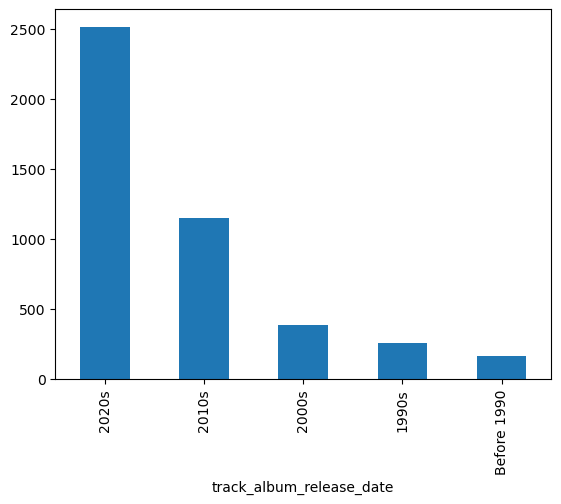

In [209]:
release_decade.value_counts().plot.bar()

## Final Processed Dataset

In [229]:
spotify_processed = spotify_cleaned.get(['track_name', 'track_artist', 'mode', 'key'])
spotify_processed = spotify_processed.assign(
    popularity=popularity_binned,
    energy=energy_binned,
    tempo=tempo_binned,
    valence=valence_binned,
    danceability=danceability_binned,
    acousticness=acousticness_binned,
    decade=release_decade,
    duration=duration_binned
)
spotify_processed.rename(
    columns={
        'track_name': 'name',
        'track_artist': 'artist',
    },
    inplace=True
)
spotify_processed.reset_index(drop=True, inplace=True)
spotify_processed

,name,artist,mode,key,popularity,energy,tempo,valence,danceability,acousticness,decade,duration
0,Die With A Smile,"Lady Gaga, Bruno Mars",0.0,6.0,"(80.0, 100.0]","(0.4, 0.6]",fast,"(0.4, 0.6]","(0.4, 0.6]","(0.2, 0.4]",2020s,4-5 min
1,BIRDS OF A FEATHER,Billie Eilish,1.0,2.0,"(80.0, 100.0]","(0.4, 0.6]",mid,"(0.4, 0.6]","(0.6, 0.8]","(-0.001, 0.2]",2020s,3-4 min
2,That’s So True,Gracie Abrams,1.0,1.0,"(80.0, 100.0]","(0.8, 1.0]",mid,"(0.2, 0.4]","(0.4, 0.6]","(0.2, 0.4]",2020s,2-3 min
3,Taste,Sabrina Carpenter,0.0,0.0,"(80.0, 100.0]","(0.8, 1.0]",mid,"(0.6, 0.8]","(0.6, 0.8]","(-0.001, 0.2]",2020s,2-3 min
4,APT.,"ROSÉ, Bruno Mars",0.0,0.0,"(80.0, 100.0]","(0.6, 0.8]",upbeat,"(0.8, 1.0]","(0.6, 0.8]","(-0.001, 0.2]",2020s,2-3 min
...,...,...,...,...,...,...,...,...,...,...,...,...
4459,Bhaja Govindam,M. S. Subbulakshmi,1.0,10.0,"(20.0, 40.0]","(0.4, 0.6]",slow,"(0.6, 0.8]","(0.2, 0.4]","(0.8, 1.0]",2010s,5+ min
4460,Varnam,Jayanthi Kumaresh,1.0,8.0,"(20.0, 40.0]","(0.2, 0.4]",upbeat,"(0.2, 0.4]","(0.4, 0.6]","(0.8, 1.0]",2000s,5+ min
4461,"Sarasuda Varnam (Raga Saveri, Aadi Tala): Jaya...","Nirmala Rajasekar, Raghavendra Rao, Tanjore K....",1.0,3.0,"(-0.001, 20.0]","(0.4, 0.6]",fast,"(0.8, 1.0]","(0.4, 0.6]","(0.8, 1.0]",2000s,5+ min
4462,Raga Karnaranjani,Ganesh & Kumaresh,0.0,8.0,"(20.0, 40.0]","(0.4, 0.6]",fast,"(0.6, 0.8]","(0.4, 0.6]","(0.8, 1.0]",2000s,4-5 min


In [230]:
spotify_processed.to_csv('data/spotify_processed.csv')

## Training/Testing Split

We'll perform an 80/20 split on the data for training/testing respectively.

In [233]:
from sklearn.model_selection import train_test_split

In [234]:
spotify_train, spotify_test = train_test_split(
    spotify_processed,
    test_size=0.2
)

In [237]:
spotify_train

,name,artist,mode,key,popularity,energy,tempo,valence,danceability,acousticness,decade,duration
2971,The Orient Is Calling,"Heiko Streicher, Stefan Heinz",0.0,6.0,"(20.0, 40.0]","(0.8, 1.0]",mid,"(0.2, 0.4]","(0.4, 0.6]","(-0.001, 0.2]",2010s,< 2 min
2496,The Other Day,halfpastseven,1.0,11.0,"(40.0, 60.0]","(0.2, 0.4]",slow,"(0.6, 0.8]","(0.6, 0.8]","(0.2, 0.4]",2020s,< 2 min
3407,The Promised Light of Life,"Cheryl Frances-Hoad, Owain Park, The Gesualdo Six",1.0,6.0,"(20.0, 40.0]","(-0.001, 0.2]",mid,"(-0.001, 0.2]","(-0.001, 0.2]","(0.8, 1.0]",2010s,2-3 min
3373,The Way of the Ghost,Ilan Eshkeri,0.0,7.0,"(40.0, 60.0]","(-0.001, 0.2]",mid,"(-0.001, 0.2]","(-0.001, 0.2]","(0.6, 0.8]",2010s,4-5 min
4090,P*Tain de m*Rde,Naza,1.0,0.0,"(40.0, 60.0]","(0.8, 1.0]",upbeat,"(0.8, 1.0]","(0.6, 0.8]","(0.2, 0.4]",2010s,3-4 min
...,...,...,...,...,...,...,...,...,...,...,...,...
2482,Fishizens,Josa,1.0,7.0,"(40.0, 60.0]","(0.2, 0.4]",slow,"(0.6, 0.8]","(0.6, 0.8]","(0.2, 0.4]",2020s,< 2 min
1093,Love Is The Only Thing,Lost Frequencies,0.0,5.0,"(60.0, 80.0]","(0.6, 0.8]",upbeat,"(0.2, 0.4]","(0.6, 0.8]","(-0.001, 0.2]",2020s,2-3 min
347,Kill Bill,SZA,1.0,8.0,"(80.0, 100.0]","(0.6, 0.8]",slow,"(0.4, 0.6]","(0.6, 0.8]","(-0.001, 0.2]",2020s,2-3 min
3914,Everything Is from You,Moshe Siegel,1.0,0.0,"(-0.001, 20.0]","(0.4, 0.6]",upbeat,"(0.2, 0.4]","(0.6, 0.8]","(-0.001, 0.2]",2010s,3-4 min


In [239]:
# The committed train/test split is canonical: every later stage depends on it, and the split
# above was made without a fixed seed. Only write the files if they don't already exist.
from pathlib import Path
if Path('data/train.csv').exists() and Path('data/test.csv').exists():
    print('data/train.csv and data/test.csv already exist: keeping the canonical split.')
else:
    spotify_train.to_csv('data/train.csv')
    spotify_test.to_csv('data/test.csv')